In [1]:
%matplotlib widget

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.ticker import MultipleLocator, FuncFormatter
from pathlib import Path

# ---------- helpers (standalone) ----------
def _to_knn(arr: np.ndarray) -> np.ndarray:
    """Coerce npy contents to shape (K,N,N)."""
    if arr.ndim == 2:
        return arr[None, ...].astype(np.float64)
    if arr.ndim != 3:
        raise ValueError(f"Unsupported rank {arr.ndim}")
    s0, s1, s2 = arr.shape
    if s1 == s2 and s0 != s1:
        out = arr
    elif s0 == s1 and s0 != s2:
        out = np.moveaxis(arr, -1, 0)
    elif s0 == s2 and s0 != s1:
        out = np.moveaxis(arr, 1, 0)
    else:
        k_axis = int(np.argmin([s0, s1, s2]))
        out = arr if k_axis == 0 else np.moveaxis(arr, k_axis, 0)
        K, N1, N2 = out.shape
        if N1 != N2:
            raise ValueError(f"Cannot coerce {arr.shape} to (K,N,N)")
    return out.astype(np.float64)

def load_zernike_stack(path: str) -> np.ndarray:
    return _to_knn(np.load(path))

def unit_disk_grid(n: int):
    xs = (np.arange(n) - (n - 1)/2.0) * (2.0/n)
    ys = (np.arange(n) - (n - 1)/2.0) * (2.0/n)
    X, Y = np.meshgrid(xs, ys, indexing="xy")
    R = np.sqrt(X**2 + Y**2)
    mask = R <= 1.0 + 1e-12
    dA = (2.0/n)**2
    return X, Y, R, mask, dA

def gaussian_on_pupil(R, mask, u0: float):
    M = np.zeros_like(R, dtype=np.float64)
    M[mask] = np.exp(-(R[mask]**2) / (u0**2))
    return M

def complex_overlap_A_precomputed(m, w, dA, a_rad):
    """
    m: mode on mask (P,), w: gaussian weights on mask (P,)
    a_rad: scalar coefficient (radians)
    """
    if w.size == 0:
        return 0j
    E = np.exp(1j * (a_rad * m))
    # normalization (same for all a)
    norm_E = np.sqrt(m.size * dA)
    norm_M = np.sqrt(np.sum(w**2) * dA)
    if norm_M == 0:
        return 0j
    return (np.sum(E * w) * dA) / (norm_E * norm_M)

# phase → colormap coordinate in [0,1)
def _phase_unit(phi):
    return ((phi + np.pi) / (2*np.pi)) % 1.0

def _fmt_pi(x, pos):
    k = int(np.round(x/np.pi))
    if abs(x/np.pi - k) > 1e-6: return ""
    if k == 0: return r"$0$"
    s = "-" if k < 0 else ""
    return rf"${s}\pi$" if abs(k) == 1 else rf"${s}{abs(k)}\pi$"

# ---------- the animation (standalone, twilight colormap) ----------
def phasor_simulation(
    zernike_path="fixedzernike_stack.npy",
    idx=1,                 # 1-based Noll index into the stack
    u0=0.30,
    coeff_max=4*np.pi,
    frames=121,
    downsample=2,
    show_animation=True,
    save_animation_path=None,  # ".gif" uses PillowWriter; ".mp4" uses ffmpeg if installed
    cmap_name="twilight",
    real_tint=True, real_eta=1e-3
):
    # --- load & prep ---
    Z = load_zernike_stack(zernike_path)
    k = idx - 1
    if not (0 <= k < Z.shape[0]):
        raise ValueError(f"idx {idx} out of range for stack with K={Z.shape[0]}")
    mode = Z[k, ::downsample, ::downsample]
    N = mode.shape[0]
    X, Y, R, mask, dA = unit_disk_grid(N)
    M = gaussian_on_pupil(R, mask, u0)

    # cache masked arrays for speed
    m = mode[mask]
    w = M[mask]

    # coefficient sweep
    c_vals = np.linspace(-coeff_max, coeff_max, frames, dtype=np.float64)

    # precompute A(c), I(c), arg(A(c)) for the strip plot & colors
    A_vals = np.array([complex_overlap_A_precomputed(m, w, dA, c) for c in c_vals])
    I_vals = np.abs(A_vals)**2
    th_vals = np.angle(A_vals)

    cmap = plt.get_cmap(cmap_name)

    # --- figure layout ---
    fig = plt.figure(figsize=(11, 6.0))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.0, 0.35], width_ratios=[1.05, 1.0, 0.25],
                          hspace=0.28, wspace=0.30)
    ax_pupil  = fig.add_subplot(gs[0,0])
    ax_arg    = fig.add_subplot(gs[0,1], aspect='equal')
    ax_strip  = fig.add_subplot(gs[1,0:2])
    ax_swatch = fig.add_subplot(gs[0,2])

    # --- initial pupil image at c0 ---
    c0 = c_vals[0]
    phase0 = np.zeros_like(R)
    phase0[mask] = c0 * mode[mask]
    # color = cmap(_phase_unit(phase))
    img_rgb = np.ones((*phase0.shape, 3), dtype=float)
    pu = _phase_unit(np.angle(np.exp(1j*phase0)))
    rgb = cmap(pu)[..., :3]
    # fade by amplitude
    amax = float(np.max(M[mask])) + 1e-15
    alpha = np.zeros_like(M); alpha[mask] = M[mask] / amax
    bg = 0.95
    img_rgb[:] = bg
    img_rgb[mask] = rgb[mask] * alpha[mask, None] + bg * (1 - alpha[mask, None])
    im = ax_pupil.imshow(img_rgb, extent=[-1,1,-1,1], origin='lower')
    rim_base = plt.Circle((0,0), 1.0, color='0.2', fill=False, lw=0.8)
    ax_pupil.add_patch(rim_base)
    rim_color = cmap(_phase_unit(th_vals[0]))
    rim = plt.Circle((0,0), 1.03, fill=False, lw=4.0, ec=rim_color)
    ax_pupil.add_patch(rim)
    ax_pupil.set_xlim(-1.05, 1.05); ax_pupil.set_ylim(-1.05, 1.05)
    ax_pupil.set_title(rf"Pupil phasors  $e^{{i\,a\,Z_{{{idx}}}}}$", pad=4)
    ax_pupil.set_xlabel("x / pupil radius"); ax_pupil.set_ylabel("y / pupil radius")

    # --- Argand plane ---
    t = np.linspace(0, 2*np.pi, 400)
    unit_rim, = ax_arg.plot(np.cos(t), np.sin(t), color=rim_color, lw=2.0)
    ax_arg.axhline(0, color='0.85', lw=0.8, zorder=0)
    ax_arg.axvline(0, color='0.85', lw=0.8, zorder=0)
    bg_tint = ax_arg.imshow([[0,0],[0,0]], extent=[-1.05,1.05,-1.05,1.05],
                            origin='lower', vmin=0, vmax=1, alpha=0.0, zorder=-2)
    A0 = A_vals[0]; col0 = rim_color
    ph_line, = ax_arg.plot([0, A0.real], [0, A0.imag], color=col0, lw=3.0)
    tip, = ax_arg.plot([A0.real], [A0.imag], 'o', color=col0, ms=7)
    ax_arg.set_xlim(-1.05, 1.05); ax_arg.set_ylim(-1.05, 1.05)
    ax_arg.set_title("Net phasor  $A(a)$")
    ax_arg.set_xlabel("Re"); ax_arg.set_ylabel("Im")
    ann = ax_arg.text(0.02, 0.98, f"|A|²={I_vals[0]:.3f}\narg(A)={th_vals[0]:+.2f} rad",
                      transform=ax_arg.transAxes, ha='left', va='top')

    # --- net-phase swatch & legend bar ---
    ax_swatch.set_title("net phase", pad=6); ax_swatch.set_xticks([]); ax_swatch.set_yticks([])
    sw = ax_swatch.imshow(np.ones((20,20,4))*np.array(rim_color)[None,None,:], aspect='auto')
    # bar -π..π
    nbar = 300
    bar_phi = np.linspace(-np.pi, np.pi, nbar)
    bar_rgb = cmap(_phase_unit(bar_phi))[None, :, :]
    ax_bar = fig.add_axes([ax_swatch.get_position().x0,
                           ax_swatch.get_position().y0 - 0.06,
                           ax_swatch.get_position().width, 0.045])
    ax_bar.imshow(bar_rgb, extent=[-np.pi, np.pi, 0, 1], aspect='auto')
    ax_bar.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax_bar.set_xticklabels([r"$-\pi$", r"$-\pi/2$", r"$0$", r"$\pi/2$", r"$\pi$"])
    ax_bar.set_yticks([])
    ax_bar.set_xlabel("arg(A)")

    # --- |A|^2 strip with π ticks ---
    strip, = ax_strip.plot(c_vals, I_vals, color='tab:orange', lw=2)
    marker, = ax_strip.plot([c0], [I_vals[0]], 'o', color=col0, ms=7)
    ax_strip.xaxis.set_major_locator(MultipleLocator(base=np.pi))
    ax_strip.xaxis.set_major_formatter(FuncFormatter(_fmt_pi))
    ax_strip.xaxis.set_minor_locator(MultipleLocator(base=np.pi/2))
    ax_strip.set_xlim(c_vals[0], c_vals[-1]); ax_strip.set_ylim(0, 1.02)
    ax_strip.set_xlabel("Zernike coefficient  a [rad]"); ax_strip.set_ylabel(r"$|A|^2$")

    # --- animation update ---
    def update(idx_frame):
        c = c_vals[idx_frame]
        # pupil colors
        phase = np.zeros_like(R); phase[mask] = c * mode[mask]
        pu = _phase_unit(np.angle(np.exp(1j*phase)))
        rgb = cmap(pu)[..., :3]
        img_rgb = np.full((*phase.shape, 3), 0.95)
        img_rgb[mask] = rgb[mask] * alpha[mask, None] + 0.95 * (1 - alpha[mask, None])
        im.set_data(img_rgb)

        A = A_vals[idx_frame]
        phi = np.angle(A); col = cmap(_phase_unit(phi))
        ph_line.set_data([0, A.real], [0, A.imag]); ph_line.set_color(col)
        tip.set_data([A.real], [A.imag]); tip.set_color(col)
        unit_rim.set_color(col); rim.set_ec(col)
        marker.set_data([c], [np.abs(A)**2]); marker.set_color(col)
        sw.set_data(np.ones((20,20,4))*np.array(col)[None,None,:])
        ann.set_text(f"|A|²={np.abs(A)**2:.3f}\narg(A)={phi:+.2f} rad")

        if real_tint:
            realish = (abs(A.imag) <= real_eta * max(abs(A), 1e-15))
            if realish:
                bg_col = (0.0, 0.6, 0.0, 1.0) if (A.real >= 0) else (0.8, 0.0, 0.0, 1.0)
                from matplotlib import colors as mcolors
                bg_tint.set_cmap(mcolors.ListedColormap([bg_col, bg_col])); bg_tint.set_alpha(0.12)
            else:
                bg_tint.set_alpha(0.0)

        return im, ph_line, tip, marker, unit_rim, rim, sw, bg_tint, ann

    ani = None
    if show_animation:
        ani = FuncAnimation(fig, update, frames=len(c_vals), interval=40, blit=False, repeat=True)

    if save_animation_path:
        ext = Path(save_animation_path).suffix.lower()
        if ani is None:
            ani = FuncAnimation(fig, update, frames=len(c_vals), interval=40, blit=False, repeat=False)
        if ext in (".gif", ".apng"):
            fps = max(1, int(round(1000/40)))  # ~25 fps
            ani.save(save_animation_path, dpi=120, writer=PillowWriter(fps=fps))
        elif ext == ".mp4":
            try:
                ani.save(save_animation_path, dpi=120, writer="ffmpeg")
            except Exception as e:
                print(f"FFMPEG not available ({e}); saving GIF instead…")
                ani.save(Path(save_animation_path).with_suffix(".gif"), dpi=120, writer=PillowWriter(fps=fps))
        else:
            print("Unsupported animation extension; use .mp4, .gif, or .apng")

    plt.show()
    return ani  # returned so you can re-save later if you wish


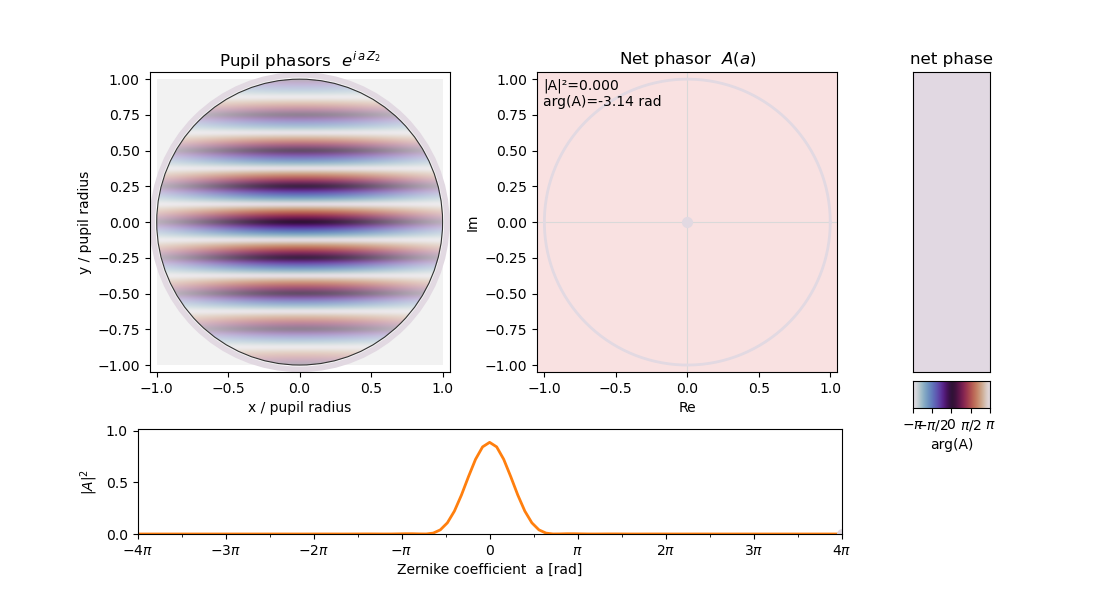

In [7]:

phasor_simulation("fixedzernike_stack3.npy", idx=2, u0=0.90, coeff_max=4*np.pi, frames=101,downsample=1, show_animation=True, save_animation_path='animation.gif')


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from matplotlib.ticker import MultipleLocator, FuncFormatter
from pathlib import Path

# ---------- minimal helpers ----------
def _to_knn(arr: np.ndarray) -> np.ndarray:
    if arr.ndim == 2: return arr[None, ...].astype(np.float64)
    if arr.ndim != 3: raise ValueError(f"Unsupported rank {arr.ndim}")
    s0,s1,s2 = arr.shape
    if s1==s2 and s0!=s1: out = arr
    elif s0==s1 and s0!=s2: out = np.moveaxis(arr,-1,0)
    elif s0==s2 and s0!=s1: out = np.moveaxis(arr,1,0)
    else:
        k_axis = int(np.argmin([s0,s1,s2]))
        out = arr if k_axis==0 else np.moveaxis(arr,k_axis,0)
        K,N1,N2 = out.shape
        if N1!=N2: raise ValueError(f"Cannot coerce {arr.shape} to (K,N,N)")
    return out.astype(np.float64)

def load_zernike_stack(path: str) -> np.ndarray:
    return _to_knn(np.load(path))

def unit_disk_grid(n: int):
    xs = (np.arange(n) - (n - 1)/2.0) * (2.0/n)
    ys = (np.arange(n) - (n - 1)/2.0) * (2.0/n)
    X, Y = np.meshgrid(xs, ys, indexing="xy")
    R = np.sqrt(X**2 + Y**2)
    mask = R <= 1.0 + 1e-12
    dA = (2.0/n)**2
    return X, Y, R, mask, dA

def gaussian_on_pupil(R, mask, u0: float):
    M = np.zeros_like(R, dtype=np.float64)
    M[mask] = np.exp(-(R[mask]**2)/(u0**2))
    return M

def complex_overlap_A_precomputed(m, w, dA, a_rad):
    # normalization constants (constant w.r.t. a)
    if w.size == 0: return 0j
    norm_E = np.sqrt(m.size * dA)
    norm_M = np.sqrt(np.sum(w**2) * dA)
    if norm_M == 0: return 0j
    E = np.exp(1j * (a_rad * m))
    return (np.sum(E * w) * dA) / (norm_E * norm_M)

# π tick formatter
def _fmt_pi(x, pos):
    k = int(np.round(x/np.pi))
    if abs(x/np.pi - k) > 1e-6: return ""
    if k == 0: return r"$0$"
    s = "-" if k < 0 else ""
    return rf"${s}\pi$" if abs(k)==1 else rf"${s}{abs(k)}\pi$"

# map phase in (-π,π] to [0,1) for cyclic colormap lookups
def _phase_unit(phi):
    return ((phi + np.pi) / (2*np.pi)) % 1.0

# ---------- slider-based interactive viewer ----------
def phasor_slider(
    zernike_path="fixedzernike_stack.npy",
    idx=1,                 # 1-based Noll index into the stack
    u0=0.30,
    coeff_max=4*np.pi,     # slider range is [-coeff_max, +coeff_max]
    frames_curve=401,      # samples for the |A|^2 strip curve
    downsample=2,
    cmap_name="twilight",  # cyclic colormap ('twilight', 'twilight_shifted', 'hsv', ...)
):
    # --- load data & precompute ---
    Z = load_zernike_stack(zernike_path)
    k = idx - 1
    if not (0 <= k < Z.shape[0]):
        raise ValueError(f"idx {idx} out of range for stack with K={Z.shape[0]}")
    mode = Z[k, ::downsample, ::downsample]
    N = mode.shape[0]
    X, Y, R, mask, dA = unit_disk_grid(N)
    M = gaussian_on_pupil(R, mask, u0)

    # masked vectors for fast overlap evaluation
    m = mode[mask]        # (P,)
    w = M[mask]           # (P,)
    amax = float(np.max(M[mask])) + 1e-15

    # coefficient sweep for the strip plot
    c_vals = np.linspace(-coeff_max, coeff_max, frames_curve, dtype=np.float64)
    A_vals = np.array([complex_overlap_A_precomputed(m, w, dA, c) for c in c_vals])
    I_vals = np.abs(A_vals)**2
    th_vals = np.angle(A_vals)

    cmap = plt.get_cmap(cmap_name)

    # --- figure layout ---
    fig = plt.figure(figsize=(11, 6.0))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.0, 0.40], width_ratios=[1.05, 1.0, 0.25],
                          hspace=0.30, wspace=0.30)
    ax_pupil  = fig.add_subplot(gs[0,0])
    ax_arg    = fig.add_subplot(gs[0,1], aspect='equal')
    ax_strip  = fig.add_subplot(gs[1,0:2])
    ax_swatch = fig.add_subplot(gs[0,2])

    # --- initial state at a0 ---
    a0 = 0.0
    phase0 = np.zeros_like(R); phase0[mask] = a0 * mode[mask]
    pu = _phase_unit(np.angle(np.exp(1j*phase0)))
    rgb = cmap(pu)[..., :3]

    bg = 0.95
    alpha = np.zeros_like(M); alpha[mask] = M[mask] / amax
    img_rgb = np.full((*R.shape, 3), bg)
    img_rgb[mask] = rgb[mask] * alpha[mask, None] + bg * (1 - alpha[mask, None])
    im = ax_pupil.imshow(img_rgb, extent=[-1,1,-1,1], origin='lower')
    rim_base = plt.Circle((0,0), 1.0, color='0.2', fill=False, lw=0.8)
    ax_pupil.add_patch(rim_base)
    rim_color = cmap(_phase_unit(0.0))
    rim = plt.Circle((0,0), 1.03, fill=False, lw=4.0, ec=rim_color)
    ax_pupil.add_patch(rim)
    ax_pupil.set_xlim(-1.05, 1.05); ax_pupil.set_ylim(-1.05, 1.05)
    ax_pupil.set_title(rf"Pupil phasors  $e^{{i\,a\,Z_{{{idx}}}}}$", pad=4)
    ax_pupil.set_xlabel("x / pupil radius"); ax_pupil.set_ylabel("y / pupil radius")

    t = np.linspace(0, 2*np.pi, 400)
    unit_rim, = ax_arg.plot(np.cos(t), np.sin(t), color=rim_color, lw=2.0)
    ax_arg.axhline(0, color='0.85', lw=0.8, zorder=0)
    ax_arg.axvline(0, color='0.85', lw=0.8, zorder=0)
    A0 = complex_overlap_A_precomputed(m, w, dA, a0)
    col0 = cmap(_phase_unit(np.angle(A0)))
    ph_line, = ax_arg.plot([0, A0.real], [0, A0.imag], color=col0, lw=3.0)
    tip, = ax_arg.plot([A0.real], [A0.imag], 'o', color=col0, ms=7)
    ax_arg.set_xlim(-1.05, 1.05); ax_arg.set_ylim(-1.05, 1.05)
    ax_arg.set_title("Net phasor  $A(a)$")
    ax_arg.set_xlabel("Re"); ax_arg.set_ylabel("Im")
    ann = ax_arg.text(0.02, 0.98, f"|A|²={np.abs(A0)**2:.3f}\narg(A)={np.angle(A0):+.2f} rad",
                      transform=ax_arg.transAxes, ha='left', va='top')

    # net-phase swatch & colormap bar
    ax_swatch.set_title("net phase", pad=6); ax_swatch.set_xticks([]); ax_swatch.set_yticks([])
    sw = ax_swatch.imshow(np.ones((20,20,4))*np.array(col0)[None,None,:], aspect='auto')
    nbar = 300
    bar_phi = np.linspace(-np.pi, np.pi, nbar)
    bar_rgb = cmap(_phase_unit(bar_phi))[None, :, :]
    ax_bar = fig.add_axes([ax_swatch.get_position().x0,
                           ax_swatch.get_position().y0 - 0.06,
                           ax_swatch.get_position().width, 0.045])
    ax_bar.imshow(bar_rgb, extent=[-np.pi, np.pi, 0, 1], aspect='auto')
    ax_bar.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax_bar.set_xticklabels([r"$-\pi$", r"$-\pi/2$", r"$0$", r"$\pi/2$", r"$\pi$"])
    ax_bar.set_yticks([])
    ax_bar.set_xlabel("arg(A)")

    # |A|^2 strip (precomputed) with π ticks + moving marker + current a line
    strip, = ax_strip.plot(c_vals, I_vals, color='tab:orange', lw=2)
    marker, = ax_strip.plot([a0], [np.abs(A0)**2], 'o', color=col0, ms=7)
    curline = ax_strip.axvline(a0, color='0.4', lw=1.0, ls='--')
    ax_strip.xaxis.set_major_locator(MultipleLocator(base=np.pi))
    ax_strip.xaxis.set_major_formatter(FuncFormatter(_fmt_pi))
    ax_strip.xaxis.set_minor_locator(MultipleLocator(base=np.pi/2))
    ax_strip.set_xlim(-coeff_max, coeff_max); ax_strip.set_ylim(0, 1.02)
    ax_strip.set_xlabel("Zernike coefficient  a [rad]"); ax_strip.set_ylabel(r"$|A|^2$")

    # --- slider ---
    ax_sl = plt.axes([0.12, 0.05, 0.76, 0.03])
    s_a = Slider(ax_sl, "a", -coeff_max, coeff_max, valinit=a0)

    def update(val):
        a = s_a.val
        # pupil
        phase = np.zeros_like(R); phase[mask] = a * mode[mask]
        pu = _phase_unit(np.angle(np.exp(1j*phase)))
        rgb = cmap(pu)[..., :3]
        img_rgb = np.full((*R.shape, 3), bg)
        img_rgb[mask] = rgb[mask] * alpha[mask, None] + bg * (1 - alpha[mask, None])
        im.set_data(img_rgb)

        # net phasor
        A = complex_overlap_A_precomputed(m, w, dA, a)
        phi = np.angle(A); col = cmap(_phase_unit(phi))
        ph_line.set_data([0, A.real], [0, A.imag]); ph_line.set_color(col)
        tip.set_data([A.real], [A.imag]); tip.set_color(col)
        unit_rim.set_color(col); rim.set_ec(col)
        marker.set_data([a], [np.abs(A)**2]); marker.set_color(col)
        curline.set_xdata([a, a])
        sw.set_data(np.ones((20,20,4))*np.array(col)[None,None,:])
        ann.set_text(f"|A|²={np.abs(A)**2:.3f}\narg(A)={phi:+.2f} rad")

        fig.canvas.draw_idle()
        return im, ph_line, tip, marker, unit_rim, rim, sw, ann, curline

    s_a.on_changed(update)
    plt.show()
    return fig


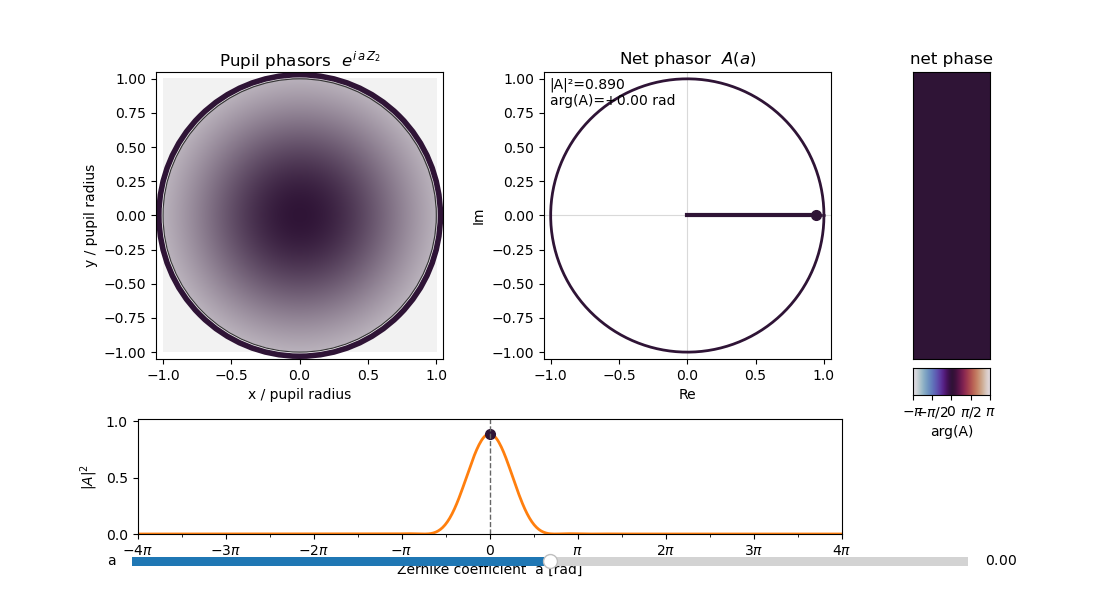

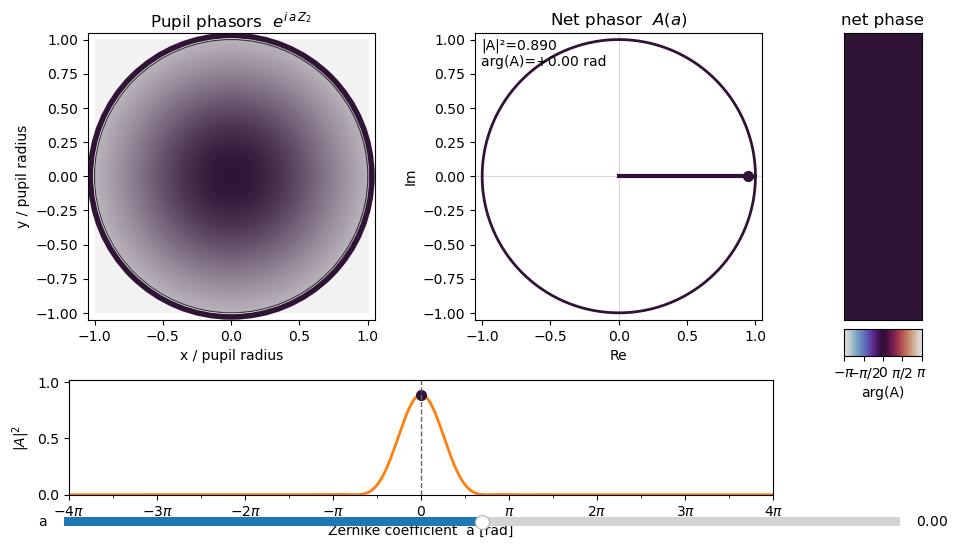

In [11]:
# Basic:
phasor_slider(
    "fixedzernike_stack3.npy",
    idx=2,            # Noll index (1-based)
    u0=0.90,
    coeff_max=4*np.pi,
    frames_curve=601, # resolution of the |A|^2 strip (precomputed)
    downsample=1,
    cmap_name="twilight"
)

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from matplotlib.ticker import MultipleLocator, FuncFormatter
from pathlib import Path

# ---------- minimal helpers ----------
def _to_knn(arr: np.ndarray) -> np.ndarray:
    if arr.ndim == 2: return arr[None, ...].astype(np.float64)
    if arr.ndim != 3: raise ValueError(f"Unsupported rank {arr.ndim}")
    s0,s1,s2 = arr.shape
    if s1==s2 and s0!=s1: out = arr
    elif s0==s1 and s0!=s2: out = np.moveaxis(arr,-1,0)
    elif s0==s2 and s0!=s1: out = np.moveaxis(arr,1,0)
    else:
        k_axis = int(np.argmin([s0,s1,s2]))
        out = arr if k_axis==0 else np.moveaxis(arr,k_axis,0)
        K,N1,N2 = out.shape
        if N1!=N2: raise ValueError(f"Cannot coerce {arr.shape} to (K,N,N)")
    return out.astype(np.float64)

def load_zernike_stack(path: str) -> np.ndarray:
    return _to_knn(np.load(path))

def unit_disk_grid(n: int):
    xs = (np.arange(n) - (n - 1)/2.0) * (2.0/n)
    ys = (np.arange(n) - (n - 1)/2.0) * (2.0/n)
    X, Y = np.meshgrid(xs, ys, indexing="xy")
    R = np.sqrt(X**2 + Y**2)
    mask = R <= 1.0 + 1e-12
    dA = (2.0/n)**2
    return X, Y, R, mask, dA

def gaussian_on_pupil(R, mask, u0: float):
    M = np.zeros_like(R, dtype=np.float64)
    M[mask] = np.exp(-(R[mask]**2)/(u0**2))
    return M

def complex_overlap_A_precomputed(m, w, dA, a_rad):
    if w.size == 0: return 0j
    norm_E = np.sqrt(m.size * dA)
    norm_M = np.sqrt(np.sum(w**2) * dA)
    if norm_M == 0: return 0j
    E = np.exp(1j * (a_rad * m))
    return (np.sum(E * w) * dA) / (norm_E * norm_M)

def _fmt_pi(x, pos):
    k = int(np.round(x/np.pi))
    if abs(x/np.pi - k) > 1e-6: return ""
    if k == 0: return r"$0$"
    s = "-" if k < 0 else ""
    return rf"${s}\pi$" if abs(k)==1 else rf"${s}{abs(k)}\pi$"

# wrap phase to (-π, π]
def _wrap_pi(phi):
    twopi = 2*np.pi
    return ((phi + np.pi) % twopi) - np.pi

# ---------- fast slider with optional precompute ----------
def phasor_slider_fast(
    zernike_path="fixedzernike_stack.npy",
    idx=1,                   # 1-based Noll index
    u0=0.30,
    coeff_max=4*np.pi,
    frames_curve=401,        # samples for |A|^2 curve (precomputed)
    downsample=2,
    cmap_name="twilight",
    precompute="none",       # 'none' | 'ram' | 'memmap'
    memmap_path="phase_frames.dat",  # used if precompute='memmap'
    dtype="float32"          # dtype for precomputed frames
):
    # --- load & prep ---
    Z = load_zernike_stack(zernike_path)
    k = idx - 1
    if not (0 <= k < Z.shape[0]):
        raise ValueError(f"idx {idx} out of range for stack with K={Z.shape[0]}")
    mode = Z[k, ::downsample, ::downsample]
    N = mode.shape[0]
    _, _, R, mask, dA = unit_disk_grid(N)
    M = gaussian_on_pupil(R, mask, u0)
    amax = float(np.max(M[mask])) + 1e-15

    # masked vectors for overlap
    m = mode[mask]; w = M[mask]

    # coefficient sweep for the strip
    c_vals = np.linspace(-coeff_max, coeff_max, frames_curve, dtype=np.float64)
    A_vals = np.array([complex_overlap_A_precomputed(m, w, dA, c) for c in c_vals])
    I_vals = np.abs(A_vals)**2
    th_vals = np.angle(A_vals)

    cmap = plt.get_cmap(cmap_name)

    # fixed per-pixel alpha (fade to bg outside pupil)
    alpha = np.zeros_like(M, dtype=np.float32)
    alpha[mask] = (M[mask] / amax).astype(np.float32)
    bg = 0.95

    # -------- optional precompute of phase frames --------
    frames = None
    if precompute.lower() in ("ram", "memmap"):
        C = frames_curve
        if precompute.lower() == "ram":
            frames = np.empty((C, N, N), dtype=dtype)
        else:
            # memmap on disk (saves RAM, great for large N or many frames)
            frames = np.memmap(memmap_path, mode="w+", dtype=dtype, shape=(C, N, N))
        # only fill inside the pupil; outside set to NaN so it's transparent
        nan_out = np.full((N, N), np.nan, dtype=dtype)
        for i, a in enumerate(c_vals):
            phi = nan_out.copy()
            phi[mask] = _wrap_pi(a * mode[mask]).astype(dtype, copy=False)
            frames[i] = phi  # memmap writes to disk; RAM keeps in memory
        # make sure memmap is flushed
        if isinstance(frames, np.memmap):
            frames.flush()

    # --- figure layout ---
    fig = plt.figure(figsize=(11, 6.0))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.0, 0.40],
                          width_ratios=[1.05, 1.0, 0.25],
                          hspace=0.30, wspace=0.30)
    ax_pupil  = fig.add_subplot(gs[0,0])
    ax_arg    = fig.add_subplot(gs[0,1], aspect='equal')
    ax_strip  = fig.add_subplot(gs[1,0:2])
    ax_swatch = fig.add_subplot(gs[0,2])

    # pupil image: let imshow apply colormap; give it phase (masked outside)
    a0 = 0.0
    if frames is not None:
        # choose the closest precomputed frame to a0
        i0 = int(np.searchsorted(c_vals, a0, side="left"))
        i0 = np.clip(i0, 0, len(c_vals)-1)
        phi0 = frames[i0]
    else:
        phi0 = np.full((N, N), np.nan, dtype=np.float32)
        phi0[mask] = _wrap_pi(a0 * mode[mask]).astype(np.float32, copy=False)

    im = ax_pupil.imshow(phi0, cmap=cmap, vmin=-np.pi, vmax=np.pi,
                         origin='lower', extent=[-1,1,-1,1], alpha=alpha)
    # subtle background
    ax_pupil.imshow(np.full((2,2), bg), extent=[-1,1,-1,1], origin='lower', zorder=-2, alpha=1.0)
    rim_base = plt.Circle((0,0), 1.0, color='0.2', fill=False, lw=0.8)
    ax_pupil.add_patch(rim_base)
    rim = plt.Circle((0,0), 1.03, fill=False, lw=4.0, ec=cmap((0.5)))  # initial color ~ pi
    ax_pupil.add_patch(rim)
    ax_pupil.set_xlim(-1.05, 1.05); ax_pupil.set_ylim(-1.05, 1.05)
    ax_pupil.set_title(rf"Pupil phasors  $e^{{i\,a\,Z_{{{idx}}}}}$", pad=4)
    ax_pupil.set_xlabel("x / pupil radius"); ax_pupil.set_ylabel("y / pupil radius")

    # Argand
    t = np.linspace(0, 2*np.pi, 400); unit_rim, = ax_arg.plot(np.cos(t), np.sin(t), color='0.5', lw=2.0)
    ax_arg.axhline(0, color='0.85', lw=0.8); ax_arg.axvline(0, color='0.85', lw=0.8)
    A0 = complex_overlap_A_precomputed(m, w, dA, a0)
    col0 = cmap(((np.angle(A0) + np.pi)/(2*np.pi)) % 1.0)
    ph_line, = ax_arg.plot([0, A0.real], [0, A0.imag], color=col0, lw=3.0)
    tip, = ax_arg.plot([A0.real], [A0.imag], 'o', color=col0, ms=7)
    ax_arg.set_xlim(-1.05, 1.05); ax_arg.set_ylim(-1.05, 1.05)
    ax_arg.set_title("Net phasor  $A(a)$")
    ax_arg.set_xlabel("Re"); ax_arg.set_ylabel("Im")
    ann = ax_arg.text(0.02, 0.98, f"|A|²={np.abs(A0)**2:.3f}\narg(A)={np.angle(A0):+.2f} rad",
                      transform=ax_arg.transAxes, ha='left', va='top')

    # phase swatch & color bar
    ax_swatch.set_title("net phase", pad=6); ax_swatch.set_xticks([]); ax_swatch.set_yticks([])
    sw = ax_swatch.imshow(np.ones((20,20,4))*np.array(col0)[None,None,:], aspect='auto')
    nbar = 300; bar_phi = np.linspace(-np.pi, np.pi, nbar)
    bar_rgb = cmap(((bar_phi + np.pi)/(2*np.pi)) % 1.0)[None, :, :]
    ax_bar = fig.add_axes([ax_swatch.get_position().x0,
                           ax_swatch.get_position().y0 - 0.06,
                           ax_swatch.get_position().width, 0.045])
    ax_bar.imshow(bar_rgb, extent=[-np.pi, np.pi, 0, 1], aspect='auto')
    ax_bar.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax_bar.set_xticklabels([r"$-\pi$", r"$-\pi/2$", r"$0$", r"$\pi/2$", r"$\pi$"])
    ax_bar.set_yticks([])
    ax_bar.set_xlabel("arg(A)")

    # |A|^2 strip
    strip, = ax_strip.plot(c_vals, I_vals, color='tab:orange', lw=2)
    marker, = ax_strip.plot([a0], [np.abs(A0)**2], 'o', color=col0, ms=7)
    curline = ax_strip.axvline(a0, color='0.4', lw=1.0, ls='--')
    ax_strip.xaxis.set_major_locator(MultipleLocator(base=np.pi))
    ax_strip.xaxis.set_major_formatter(FuncFormatter(_fmt_pi))
    ax_strip.xaxis.set_minor_locator(MultipleLocator(base=np.pi/2))
    ax_strip.set_xlim(-coeff_max, coeff_max); ax_strip.set_ylim(0, 1.02)
    ax_strip.set_xlabel("Zernike coefficient  a [rad]"); ax_strip.set_ylabel(r"$|A|^2$")

    # --- slider ---
    ax_sl = plt.axes([0.12, 0.05, 0.76, 0.03])
    s_a = Slider(ax_sl, "a", -coeff_max, coeff_max, valinit=a0)

    def update(a):
        # pupil phase image (fast path)
        if frames is not None:
            i = int(np.searchsorted(c_vals, a, side="left"))
            i = np.clip(i, 0, len(c_vals)-1)
            im.set_data(frames[i])
        else:
            # compute wrapped phase only inside pupil
            phi = np.full((N, N), np.nan, dtype=np.float32)
            phi[mask] = _wrap_pi(a * mode[mask]).astype(np.float32, copy=False)
            im.set_data(phi)

        # net phasor & strip marker
        A = complex_overlap_A_precomputed(m, w, dA, a)
        color = cmap(((np.angle(A) + np.pi)/(2*np.pi)) % 1.0)
        ph_line.set_data([0, A.real], [0, A.imag]); ph_line.set_color(color)
        tip.set_data([A.real], [A.imag]); tip.set_color(color)
        rim.set_ec(color)
        marker.set_data([a], [np.abs(A)**2]); marker.set_color(color)
        curline.set_xdata([a, a])
        sw.set_data(np.ones((20,20,4))*np.array(color)[None,None,:])
        ann.set_text(f"|A|²={np.abs(A)**2:.3f}\narg(A)={np.angle(A):+.2f} rad")

        fig.canvas.draw_idle()

    s_a.on_changed(update)
    plt.show()
    return fig

In [7]:
%matplotlib widget 

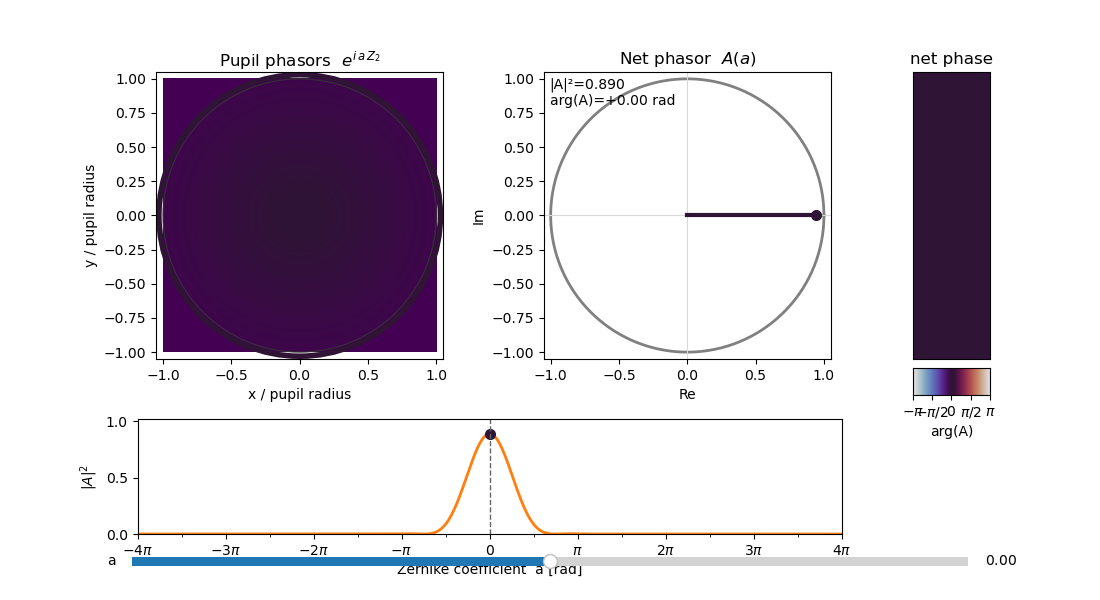

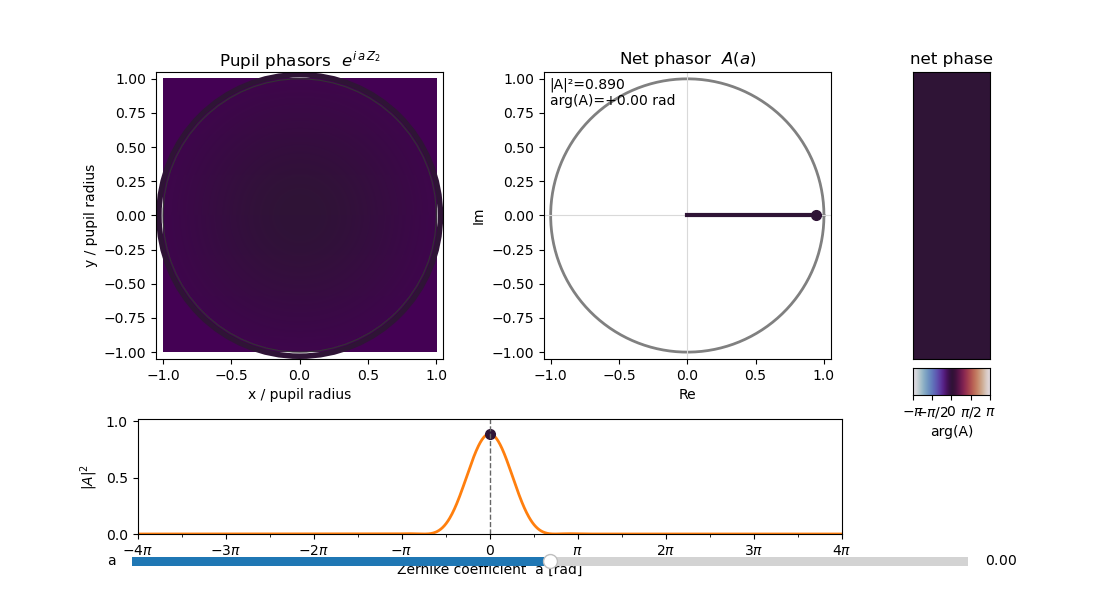

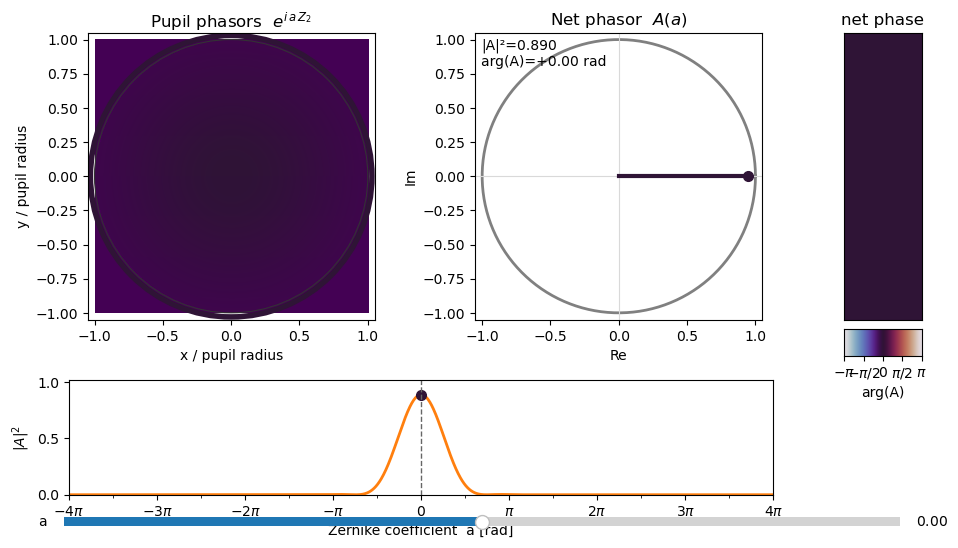

In [15]:
# Fast path (no huge precompute; should already feel smooth):
phasor_slider_fast(
    "fixedzernike_stack3.npy", idx=2, u0=0.90,
    coeff_max=4*np.pi, frames_curve=801, downsample=1,
    cmap_name="twilight", precompute="none"
)

# Ultra-smooth with RAM precompute (watch memory):
phasor_slider_fast(
    "fixedzernike_stack3.npy", idx=2, u0=0.90,
    coeff_max=4*np.pi, frames_curve=1201, downsample=1,
    precompute="ram"   # or 'memmap' to precompute to disk
)


In [17]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from matplotlib.ticker import MultipleLocator, FuncFormatter

# --- helpers (unchanged) ---
def _to_knn(arr: np.ndarray) -> np.ndarray:
    if arr.ndim == 2: return arr[None, ...].astype(np.float64)
    if arr.ndim != 3: raise ValueError(f"Unsupported rank {arr.ndim}")
    s0,s1,s2 = arr.shape
    if s1==s2 and s0!=s1: out = arr
    elif s0==s1 and s0!=s2: out = np.moveaxis(arr,-1,0)
    elif s0==s2 and s0!=s1: out = np.moveaxis(arr,1,0)
    else:
        k_axis = int(np.argmin([s0,s1,s2]))
        out = arr if k_axis==0 else np.moveaxis(arr,k_axis,0)
        K,N1,N2 = out.shape
        if N1!=N2: raise ValueError(f"Cannot coerce {arr.shape} to (K,N,N)")
    return out.astype(np.float64)

def load_zernike_stack(path: str) -> np.ndarray:
    return _to_knn(np.load(path))

def unit_disk_grid(n: int):
    xs = (np.arange(n) - (n - 1)/2.0) * (2.0/n)
    ys = (np.arange(n) - (n - 1)/2.0) * (2.0/n)
    X, Y = np.meshgrid(xs, ys, indexing="xy")
    R = np.sqrt(X**2 + Y**2)
    mask = R <= 1.0 + 1e-12
    dA = (2.0/n)**2
    return X, Y, R, mask, dA

def gaussian_on_pupil(R, mask, u0: float):
    M = np.zeros_like(R, dtype=np.float64)
    M[mask] = np.exp(-(R[mask]**2)/(u0**2))
    return M

def complex_overlap_A_precomputed(m, w, dA, a_rad):
    if w.size == 0: return 0j
    norm_E = np.sqrt(m.size * dA)
    norm_M = np.sqrt(np.sum(w**2) * dA)
    if norm_M == 0: return 0j
    E = np.exp(1j * (a_rad * m))
    return (np.sum(E * w) * dA) / (norm_E * norm_M)

def _fmt_pi(x, pos):
    k = int(np.round(x/np.pi))
    if abs(x/np.pi - k) > 1e-6: return ""
    if k == 0: return r"$0$"
    s = "-" if k < 0 else ""
    return rf"${s}\pi$" if abs(k)==1 else rf"${s}{abs(k)}\pi$"

def _wrap_pi(phi):
    twopi = 2*np.pi
    return ((phi + np.pi) % twopi) - np.pi

# --- slider viewer (fast path; uses imshow colormap and 2D alpha) ---
def phasor_slider_fast(
    zernike_path="fixedzernike_stack.npy",
    idx=1,
    u0=0.30,
    coeff_max=4*np.pi,
    frames_curve=401,
    downsample=2,
    cmap_name="twilight",
    precompute="none",       # 'none' | 'ram'
):
    # warn if backend is not interactive
    bk = matplotlib.get_backend().lower()
    if ("inline" in bk) or ("agg" in bk):
        print("[note] Your backend is non-interactive "
              f"({matplotlib.get_backend()}). Use %matplotlib widget / notebook / qt.")

    Z = load_zernike_stack(zernike_path)
    k = idx - 1
    if not (0 <= k < Z.shape[0]):
        raise ValueError(f"idx {idx} out of range (K={Z.shape[0]})")
    mode = Z[k, ::downsample, ::downsample]
    N = mode.shape[0]
    _, _, R, mask, dA = unit_disk_grid(N)
    M = gaussian_on_pupil(R, mask, u0)
    amax = float(np.max(M[mask])) + 1e-15

    m = mode[mask]; w = M[mask]
    c_vals = np.linspace(-coeff_max, coeff_max, frames_curve, dtype=np.float64)
    A_vals = np.array([complex_overlap_A_precomputed(m, w, dA, c) for c in c_vals])
    I_vals = np.abs(A_vals)**2

    cmap = plt.get_cmap(cmap_name)

    # optional precompute of phase frames into RAM
    frames = None
    if precompute.lower() == "ram":
        frames = np.full((frames_curve, N, N), np.nan, dtype=np.float32)
        for i, a in enumerate(c_vals):
            frames[i][mask] = _wrap_pi(a * mode[mask]).astype(np.float32, copy=False)

    # figure
    fig = plt.figure(figsize=(11, 6.0))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 0.40], hspace=0.30, wspace=0.30)
    ax_pupil  = fig.add_subplot(gs[0,0])
    ax_strip  = fig.add_subplot(gs[1,0])
    ax_arg    = fig.add_subplot(gs[0,1], aspect='equal')
    ax_dummy  = fig.add_subplot(gs[1,1]) ; ax_dummy.axis("off")

    # pupil: let imshow colorize phase; supply 2D alpha for Gaussian fade
    a0 = 0.0
    phi0 = np.full((N, N), np.nan, dtype=np.float32)
    phi0[mask] = _wrap_pi(a0 * mode[mask]).astype(np.float32, copy=False)
    alpha = np.zeros_like(M, dtype=np.float32); alpha[mask] = (M[mask]/amax).astype(np.float32)
    im = ax_pupil.imshow(phi0, cmap=cmap, vmin=-np.pi, vmax=np.pi,
                         origin='lower', extent=[-1,1,-1,1], alpha=alpha)
    ax_pupil.add_patch(plt.Circle((0,0), 1.0, color='0.2', fill=False, lw=0.8))
    rim = plt.Circle((0,0), 1.03, fill=False, lw=4.0, ec=cmap(0.5))
    ax_pupil.add_patch(rim)
    ax_pupil.set_xlim(-1.05, 1.05); ax_pupil.set_ylim(-1.05, 1.05)
    ax_pupil.set_title(rf"Pupil phasors  $e^{{i\,a\,Z_{{{idx}}}}}$")

    # |A|^2 strip + marker
    strip, = ax_strip.plot(c_vals, I_vals, color='tab:orange', lw=2)
    marker, = ax_strip.plot([a0], [np.abs(A_vals[0])**2], 'o', color='tab:orange', ms=7)
    curline = ax_strip.axvline(a0, color='0.4', lw=1.0, ls='--')
    ax_strip.xaxis.set_major_locator(MultipleLocator(base=np.pi))
    ax_strip.xaxis.set_major_formatter(FuncFormatter(_fmt_pi))
    ax_strip.xaxis.set_minor_locator(MultipleLocator(base=np.pi/2))
    ax_strip.set_xlim(-coeff_max, coeff_max); ax_strip.set_ylim(0, 1.02)
    ax_strip.set_xlabel("Zernike coefficient  a [rad]"); ax_strip.set_ylabel(r"$|A|^2$")

    # Argand
    t = np.linspace(0, 2*np.pi, 400)
    ax_arg.plot(np.cos(t), np.sin(t), color='0.6', lw=1.5)
    A0 = A_vals[0]
    ph_line, = ax_arg.plot([0, A0.real], [0, A0.imag], color='tab:blue', lw=3.0)
    tip, = ax_arg.plot([A0.real], [A0.imag], 'o', color='tab:blue', ms=7)
    ax_arg.axhline(0, color='0.85', lw=0.8); ax_arg.axvline(0, color='0.85', lw=0.8)
    ax_arg.set_xlim(-1.05, 1.05); ax_arg.set_ylim(-1.05, 1.05)
    ax_arg.set_title("Net phasor  $A(a)$")

    # slider
    ax_sl = plt.axes([0.12, 0.05, 0.76, 0.03])
    s_a = Slider(ax_sl, "a", -coeff_max, coeff_max, valinit=a0)
    fig._slider = s_a   # keep a strong reference to avoid GC

    def update(val):
        a = s_a.val
        # pupil phase
        if frames is not None:
            i = int(np.searchsorted(c_vals, a, side="left"))
            i = np.clip(i, 0, len(c_vals)-1)
            im.set_data(frames[i])
        else:
            phi = np.full((N, N), np.nan, dtype=np.float32)
            phi[mask] = _wrap_pi(a * mode[mask]).astype(np.float32, copy=False)
            im.set_data(phi)

        # net phasor & strip marker
        A = complex_overlap_A_precomputed(m, w, dA, a)
        ph_line.set_data([0, A.real], [0, A.imag])
        tip.set_data([A.real], [A.imag])
        marker.set_data([a], [np.abs(A)**2])
        curline.set_xdata([a, a])
        fig.canvas.draw_idle()

    s_a.on_changed(update)
    plt.show()
    return fig, s_a


In [24]:
import matplotlib
matplotlib.get_backend()

'module://ipympl.backend_nbagg'

In [29]:
%matplotlib qt 

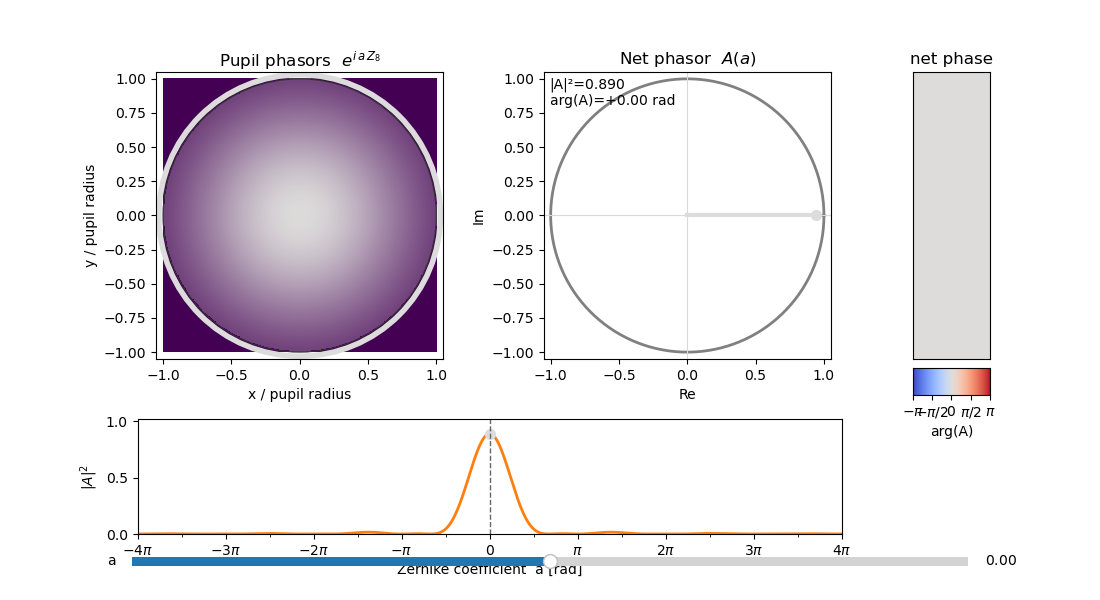

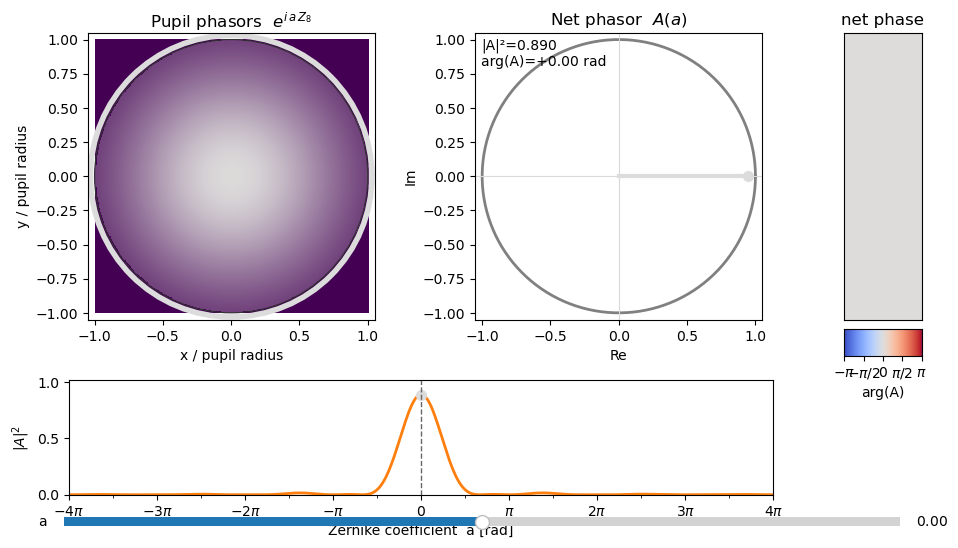

In [26]:
# Ultra-smooth with RAM precompute (watch memory):
phasor_slider_fast(
    "fixedzernike_stack3.npy", idx=8, u0=0.90,
    coeff_max=4*np.pi, frames_curve=501, downsample=2,
    precompute="ram",
    cmap_name="coolwarm"
    )


In [ ]:
pip install "cupy-cuda12x"

In [9]:
def phase_and_intensity_vs_coeff_vec_gpu(
    mode2d, R, mask, dA, u0, c_vals,
    *, chunk_size=None,  # number of coefficients per GPU chunk
):
    """
    GPU version using CuPy. Returns (theta, I, A) as NumPy arrays.
    Falls back to CPU if cupy is unavailable.
    """
    # ---- try GPU ----
    try:
        import cupy as cp
    except Exception:
        # graceful fallback to your CPU vectorized path
        return phase_and_intensity_vs_coeff_vec(
            mode2d, R, mask, dA, u0, c_vals, chunk_size=chunk_size, show_progress=False
        )

    # weights on pupil (CPU)
    M = gaussian_on_pupil(R, mask, u0)
    w_np = M[mask].astype(np.float64, copy=False)
    m_np = mode2d[mask].astype(np.float64, copy=False)
    P = m_np.size
    C = len(c_vals)

    # norms (CPU once)
    norm_E = (P * dA)**0.5
    norm_M = (np.sum(w_np**2) * dA)**0.5
    if norm_M == 0.0 or P == 0:
        th = np.zeros(C); I = np.zeros(C); A = np.zeros(C, dtype=np.complex128)
        return th, I, A
    scale = dA / (norm_E * norm_M)

    # choose chunk (VRAM control). 16 bytes per complex128 element.
    if chunk_size is None:
        # target ~256 MB temporary (P x chunk) on device
        target_bytes = 256 * 1024**2
        chunk_size = max(1, min(C, target_bytes // (P * 16)))

    # move static vectors to GPU once
    m = cp.asarray(m_np)            # (P,)
    w = cp.asarray(w_np)            # (P,)
    A_out = cp.empty((C,), dtype=cp.complex128)

    # stream through coefficients in chunks
    # E_chunk = exp(1j * m[:,None] * c[None,:]); A_chunk = (w.T @ E_chunk) * scale
    start = 0
    while start < C:
        stop = min(start + chunk_size, C)
        c_block = cp.asarray(c_vals[start:stop], dtype=cp.float64)  # (B,)
        # outer product (P,B)
        phase = m[:, None] * c_block[None, :]
        E = cp.exp(1j * phase)
        # reduction across pixels → (B,)
        A_block = (w @ E) * scale
        A_out[start:stop] = A_block
        start = stop

    # back to NumPy for plotting
    A_np = cp.asnumpy(A_out)
    th = np.angle(A_np)
    I = np.abs(A_np)**2
    return th, I, A_np

In [ ]:
phasor_slider_fast(
    "fixedzernike_stack3.npy", idx=8, u0=0.90,
    coeff_max=4*np.pi, frames_curve=501, downsample=2,
    precompute="ram",
    cmap_name="coolwarm"
    )